# Lab 1. Sealed and green surfaces around Stirling from Sentinel-1 and Sentinel-2

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yunusserhat/eo-gis-practicals/blob/main/notebooks/lab1_sealed_and_green_surfaces.ipynb)

In this practical you will map sealed surfaces, green space and water around Stirling from free satellite data.
You will combine optical images from Sentinel-2 with radar images from Sentinel-1, train a random forest classifier
and then use a GIS overlay to ask how green the town's parks and playing fields look from space.

The workflow is a simplified, teaching version of the radar and optical fusion approach in Bıçakçı (2026),
*International Journal of Environment and Geoinformatics*, in press.

**Learning outcomes.** By the end of the lab you should be able to
1. find and load Sentinel-1 and Sentinel-2 data for a study area from a STAC catalogue,
2. build a cloud-free composite and calculate spectral indices,
3. train and test a land cover classifier and read a confusion matrix,
4. combine a raster result with vector data in a GIS overlay.

**Level and time.** Honours (SCQF level 10) or MSc (SCQF level 11), about two hours.

**What you need.** A Python environment built from `requirements.txt`, or Google Colab with a Google account. No
other accounts or keys are needed. The data come from the Microsoft Planetary Computer and Ordnance Survey and take
about two minutes to download.

**How the lab works.** Each section follows five steps.
- **Predict.** Before you run a cell, write down what you expect to see.
- **Run.** Run the cell.
- **Investigate.** Compare the result with your prediction and answer the questions.
- **Modify.** Change one thing and run it again.
- **Make.** At the end you apply the workflow to a new place on your own.

**Running on Google Colab?** The next cell installs the few packages that Colab lacks, which takes about a minute.
On your own computer it does nothing.

In [1]:
# Copyright (C) 2026 Yunus Serhat Bıçakçı
# SPDX-License-Identifier: GPL-3.0-or-later
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pystac-client", "planetary-computer",
                    "odc-stac", "rioxarray", "pyogrio"], check=True)

In [2]:
import warnings
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray  # noqa: F401, adds the .rio accessor used to write GeoTIFFs
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from shapely.geometry import box
from rasterio.features import geometry_mask
import pystac_client
import planetary_computer
from odc.stac import load
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

# Medians over cloudy pixels produce empty slices. These warnings are expected and safe to ignore.
warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = Path.cwd() if IN_COLAB else Path("..")  # on Colab, files go into the session folder
DATA = ROOT / "data"
FIGURES = ROOT / "figures"
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

## 1. Study area and search for images

The study area is a box of about 10 by 9 km around Stirling. It includes the town centre, the university campus with
Airthrey Loch, the River Forth and farmland on the Carse of Stirling. We work in the British National Grid
(EPSG 27700), so every distance is in metres.

A STAC catalogue lists satellite images with their dates, footprints and cloud cover, so we can search for scenes
before downloading anything.

**Predict.** Scotland is cloudy. How many summer 2025 scenes with less than 35% cloud do you expect to find?

In [3]:
BBOX = (-4.02, 56.09, -3.86, 56.17)  # west, south, east and north edges in degrees
CRS = "EPSG:27700"                   # British National Grid
RESOLUTION = 10                      # pixel size in metres
SEASON = "2025-06-01/2025-08-31"     # leaf-on season

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)
s2_items = list(
    catalog.search(collections=["sentinel-2-l2a"], bbox=BBOX, datetime=SEASON,
                   query={"eo:cloud_cover": {"lt": 35}}).items()
)
scenes = pd.DataFrame({
    "date": [item.properties["datetime"][:10] for item in s2_items],
    "cloud_cover_percent": [round(item.properties["eo:cloud_cover"], 1) for item in s2_items],
    "processing_baseline": [item.properties["s2:processing_baseline"] for item in s2_items],
}).sort_values("date").reset_index(drop=True)
scenes

,date,cloud_cover_percent,processing_baseline
0,2025-06-10,30.1,05.11
1,2025-07-07,32.5,05.11
2,2025-08-02,21.6,05.11
3,2025-08-14,32.7,05.11
4,2025-08-17,2.4,05.11


## 2. A cloud-free Sentinel-2 composite

Each Sentinel-2 Level-2A scene comes with a scene classification layer (SCL) that flags clouds and their shadows.
We keep only pixels flagged as vegetation, bare soil, water or unclassified, and then take the median of the
remaining observations for each pixel.

Since processing baseline 04.00 (January 2022) the digital numbers carry an offset of 1000. Reflectance is therefore
(DN minus 1000) divided by 10,000. Forgetting this offset is a common error that distorts every index you calculate.

**Predict.** Which parts of the true colour image will look brightest in band 8, the near infrared?

In [4]:
assert all(float(item.properties["s2:processing_baseline"]) >= 4.0 for item in s2_items), \
    "Older scenes do not carry the offset of 1000. Remove the offset for them."

BANDS = ["B02", "B03", "B04", "B08", "B11", "B12"]
s2 = load(s2_items, bands=BANDS + ["SCL"], bbox=BBOX, crs=CRS, resolution=RESOLUTION,
          groupby="solar_day", resampling={"SCL": "nearest", "*": "bilinear"})
clear = s2.SCL.isin([4, 5, 6, 7])
reflectance = (s2[BANDS].where(clear).astype("float32") - 1000) / 10000
composite = reflectance.median("time")

print("Image size (rows, columns):", composite.B04.shape)
print("Share of clear observations on each date:", clear.mean(("x", "y")).round(2).values)
print("Pixels with no clear observation at all:", int(np.isnan(composite.B04).sum().item()))

Image size (rows, columns): (919, 1020)
Share of clear observations on each date: [0.46 1.   0.87 0.85 0.98]
Pixels with no clear observation at all: 240


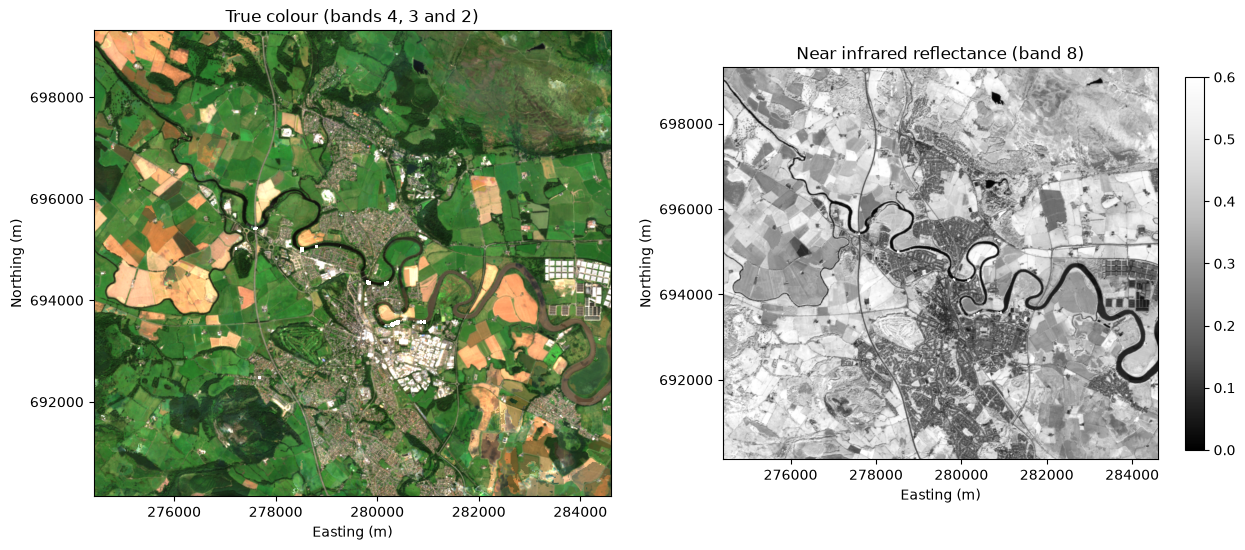

In [5]:
extent = [float(composite.x.min()), float(composite.x.max()), float(composite.y.min()), float(composite.y.max())]
rgb = np.clip(composite[["B04", "B03", "B02"]].to_array().transpose("y", "x", "variable").values / 0.15, 0, 1)
nir = composite.B08.values

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].imshow(rgb, extent=extent)
axes[0].set_title("True colour (bands 4, 3 and 2)")
im = axes[1].imshow(nir, extent=extent, cmap="Greys_r", vmin=0, vmax=0.6)
axes[1].set_title("Near infrared reflectance (band 8)")
fig.colorbar(im, ax=axes[1], shrink=0.8)
for ax in axes:
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
plt.tight_layout()
fig.savefig(FIGURES / "lab1_true_colour_and_nir.png", dpi=120)
plt.show()

**Investigate.** Were you right about band 8? Healthy leaves reflect strongly in the near infrared, while water
absorbs it. Where do roofs and roads sit between these two?

## 3. Spectral indices

Indices combine two bands so that one surface type stands out.
- NDVI = (B8 minus B4) / (B8 plus B4) is high for vegetation.
- NDBI = (B11 minus B8) / (B11 plus B8) tends to be high for built surfaces.
- MNDWI = (B3 minus B11) / (B3 plus B11) is high for open water.

**Predict.** Write down the NDVI you expect for Airthrey Loch, Stirling railway station, farmland on the Carse of
Stirling and the woodland around the Wallace Monument. Then run the cell.

In [6]:
def normalised_difference(a, b):
    return (a - b) / (a + b)

indices = xr.Dataset({
    "NDVI": normalised_difference(composite.B08, composite.B04),
    "NDBI": normalised_difference(composite.B11, composite.B08),
    "MNDWI": normalised_difference(composite.B03, composite.B11),
})

places = gpd.GeoDataFrame(
    {"place": ["Airthrey Loch", "Stirling railway station", "Farmland on the Carse of Stirling",
               "Woodland at the Wallace Monument"]},
    geometry=gpd.points_from_xy([-3.9227, -3.9358, -3.9900, -3.9165], [56.1471, 56.1196, 56.1350, 56.1375]),
    crs="EPSG:4326",
).to_crs(CRS)
at_places = indices.sel(x=xr.DataArray(places.geometry.x.values, dims="place"),
                        y=xr.DataArray(places.geometry.y.values, dims="place"), method="nearest")
pd.DataFrame({name: at_places[name].values.round(2) for name in indices.data_vars}, index=places.place)

,NDVI,NDBI,MNDWI
place,,,
Airthrey Loch,-0.09,-0.11,0.44
Stirling railway station,0.07,0.07,-0.20
Farmland on the Carse of Stirling,0.89,-0.33,-0.57
Woodland at the Wallace Monument,0.89,-0.28,-0.69


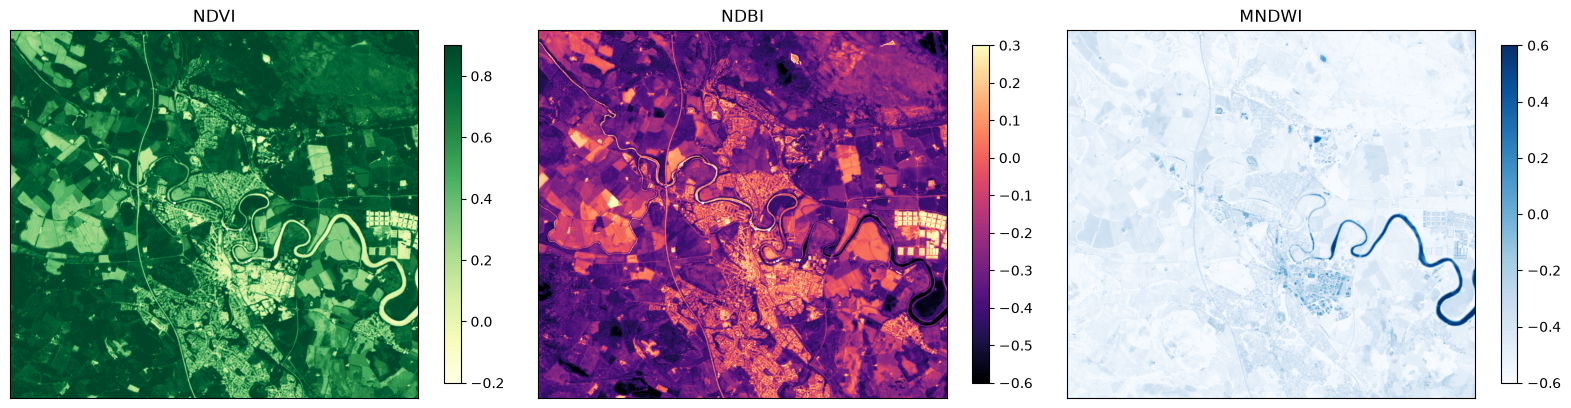

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, cmap, lims) in zip(axes, [("NDVI", "YlGn", (-0.2, 0.9)), ("NDBI", "magma", (-0.6, 0.3)),
                                          ("MNDWI", "Blues", (-0.6, 0.6))]):
    im = ax.imshow(indices[name].values, extent=extent, cmap=cmap, vmin=lims[0], vmax=lims[1])
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout()
plt.show()

**Investigate.** Which index separates the station from the farmland best? Is any index enough on its own to
separate all three classes?

## 4. Sentinel-1 radar

Sentinel-1 sends microwaves to the ground and measures what comes back, so it sees through cloud. We use the
radiometrically terrain-corrected product from descending passes over the same summer, and take the median of each
polarisation. Backscatter is converted to decibels, 10 times the base 10 logarithm of the linear value.

**Predict.** Will Airthrey Loch look bright or dark in VV radar? What about the town centre?

Radar scenes used: 30


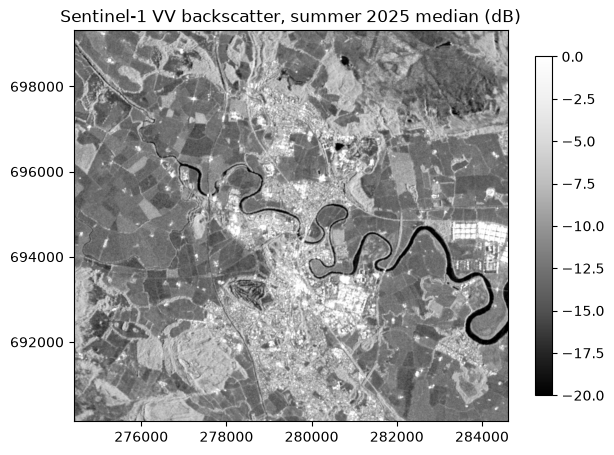

In [8]:
s1_items = [item for item in catalog.search(collections=["sentinel-1-rtc"], bbox=BBOX, datetime=SEASON).items()
            if item.properties.get("sat:orbit_state") == "descending"]
s1 = load(s1_items, bands=["vv", "vh"], like=s2, groupby="solar_day")
s1 = s1.where(s1 > 0).median("time")
radar = xr.Dataset({"VV_dB": 10 * np.log10(s1.vv), "VH_dB": 10 * np.log10(s1.vh)})
print("Radar scenes used:", len(s1_items))

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(radar.VV_dB.values, extent=extent, cmap="Greys_r", vmin=-20, vmax=0)
ax.set_title("Sentinel-1 VV backscatter, summer 2025 median (dB)")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

**Investigate.** Calm water reflects the radar pulse away from the satellite, so it looks dark. Walls and the
ground in front of them form corners that send the pulse straight back, so buildings look bright. Why might this
help where optical bands confuse dark roofs with water?

## 5. Reference labels from ESA WorldCover

A classifier needs examples of each class. Here we take them from ESA WorldCover 2021, a global 10 m land cover map,
and merge its classes into three.
- **Sealed.** Built-up land.
- **Green.** Tree cover, shrubland, grassland, cropland and herbaceous wetland.
- **Water.** Permanent water bodies.

Keep in mind that WorldCover is itself a model output, made from 2021 Sentinel-1 and Sentinel-2 data. Our labels
are therefore four years older than our images and contain their own errors. We return to this in the questions.

In [9]:
wc_items = [item for item in catalog.search(collections=["esa-worldcover"], bbox=BBOX).items() if "2021" in item.id]
worldcover = load(wc_items, bands=["map"], like=s2, resampling="nearest")["map"].isel(time=0)

CLASSES = {1: "sealed", 2: "green", 3: "water"}
COLOURS = ["#5f5f5f", "#1b9e77", "#2c7fb8"]
labels = xr.zeros_like(worldcover, dtype="uint8")
labels = labels.where(~worldcover.isin([50]), 1)
labels = labels.where(~worldcover.isin([10, 20, 30, 40, 90]), 2)
labels = labels.where(~worldcover.isin([80]), 3)
counts = pd.Series(labels.values.ravel()).map({0: "other", **CLASSES}).value_counts()
counts.to_frame("pixels")

,pixels
green,819713
sealed,93628
water,23465
other,574


## 6. Training polygons

In a real project you would digitise training polygons in QGIS, a few dozen areas of each class that you are sure
about. Here we imitate that by placing small 50 by 50 m squares where at least 80% of the WorldCover pixels share
one class, and keeping the squares at least 150 m apart. Every pixel inside a square of the right class becomes a
training pixel.

The squares are saved as a GeoPackage, so you can open `data/training_polygons.gpkg` in QGIS and check them
against the true colour image.

**Modify.** Later, change the number of squares per class in `TARGETS` and see what happens to the accuracy.

In [10]:
stack = xr.merge([composite, indices, radar], compat="override")
FEATURES = BANDS + ["NDVI", "NDBI", "MNDWI", "VV_dB", "VH_dB"]
TARGETS = {1: 60, 2: 60, 3: 20}  # squares per class
HALF = 2                          # 2 pixels each side, so squares are 5 by 5 pixels
MIN_SPACING = 15                  # minimum distance between square centres, in pixels (150 m)

rng = np.random.default_rng(42)
lab = labels.values
H, W = lab.shape
centres, rows = [], []
for k, n in TARGETS.items():
    ys, xs = np.nonzero(lab == k)
    taken = 0
    for j in rng.permutation(ys.size):
        y0, x0 = ys[j], xs[j]
        if y0 < HALF or x0 < HALF or y0 >= H - HALF or x0 >= W - HALF:
            continue
        if (lab[y0 - HALF:y0 + HALF + 1, x0 - HALF:x0 + HALF + 1] == k).mean() < 0.8:
            continue
        if centres and np.min(np.hypot(*(np.array(centres) - (y0, x0)).T)) < MIN_SPACING:
            continue
        centres.append((y0, x0))
        polygon_id = len(centres) - 1
        for dy in range(-HALF, HALF + 1):
            for dx in range(-HALF, HALF + 1):
                if lab[y0 + dy, x0 + dx] == k:
                    rows.append((polygon_id, k, y0 + dy, x0 + dx))
        taken += 1
        if taken == n:
            break

train = pd.DataFrame(rows, columns=["polygon_id", "label", "row", "col"])
train["E"] = stack.x.values[train.col]
train["N"] = stack.y.values[train.row]
for name in FEATURES:
    train[name] = stack[name].values[train.row, train.col]
train = train.dropna(subset=FEATURES).reset_index(drop=True)

half_size = (HALF + 0.5) * RESOLUTION
polygons = gpd.GeoDataFrame(
    {"polygon_id": range(len(centres)),
     "class": [CLASSES[int(lab[y, x])] for y, x in centres]},
    geometry=[box(stack.x.values[x] - half_size, stack.y.values[y] - half_size,
                  stack.x.values[x] + half_size, stack.y.values[y] + half_size) for y, x in centres],
    crs=CRS,
)
polygons.to_file(DATA / "training_polygons.gpkg", layer="training_polygons", driver="GPKG")
print(f"{len(polygons)} training squares and {len(train)} training pixels")
train.groupby("label").agg(squares=("polygon_id", "nunique"), pixels=("polygon_id", "size")).rename(index=CLASSES)

140 training squares and 3340 training pixels


,squares,pixels
label,,
sealed,60,1392
green,60,1486
water,20,462


## 7. Train and test a random forest

A random forest builds many decision trees on random subsets of the data and lets them vote. Here we follow the
approach of many tutorials and hold back a random 30% of the training pixels as a test set.

**Predict.** What overall accuracy do you expect? Write the number down before you run the cell.

Overall accuracy 0.977
Macro F1 score 0.981


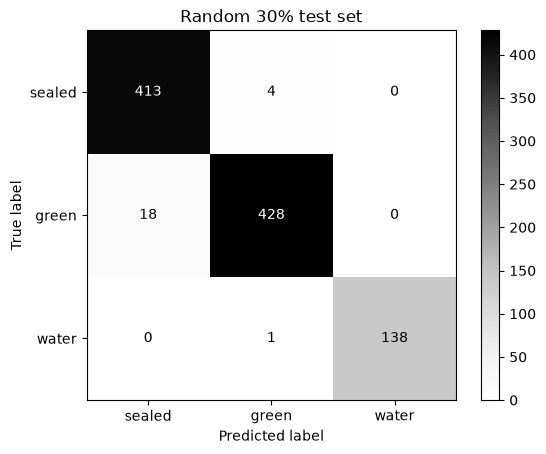

In [11]:
X = train[FEATURES].values
y = train["label"].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
forest = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_train, y_train)
predicted = forest.predict(X_test)
print(f"Overall accuracy {accuracy_score(y_test, predicted):.3f}")
print(f"Macro F1 score {f1_score(y_test, predicted, average='macro'):.3f}")
ConfusionMatrixDisplay.from_predictions(y_test, predicted, display_labels=list(CLASSES.values()), cmap="Greys")
plt.title("Random 30% test set")
plt.show()

**Investigate.** Which classes are confused with each other, and why might that be? Keep your accuracy figure.
Lab 2 asks whether it can be trusted.

**Modify.** Remove the two radar bands and run the cell below. Does radar help here?

In [12]:
optical_only = [FEATURES.index(name) for name in FEATURES if name not in ("VV_dB", "VH_dB")]
forest_optical = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
forest_optical.fit(X_train[:, optical_only], y_train)
print(f"Optical bands only, overall accuracy "
      f"{accuracy_score(y_test, forest_optical.predict(X_test[:, optical_only])):.3f}")

Optical bands only, overall accuracy 0.977


## 8. Map the whole study area

We now apply the forest to every pixel and save the result as a GeoTIFF in the British National Grid, ready for QGIS.

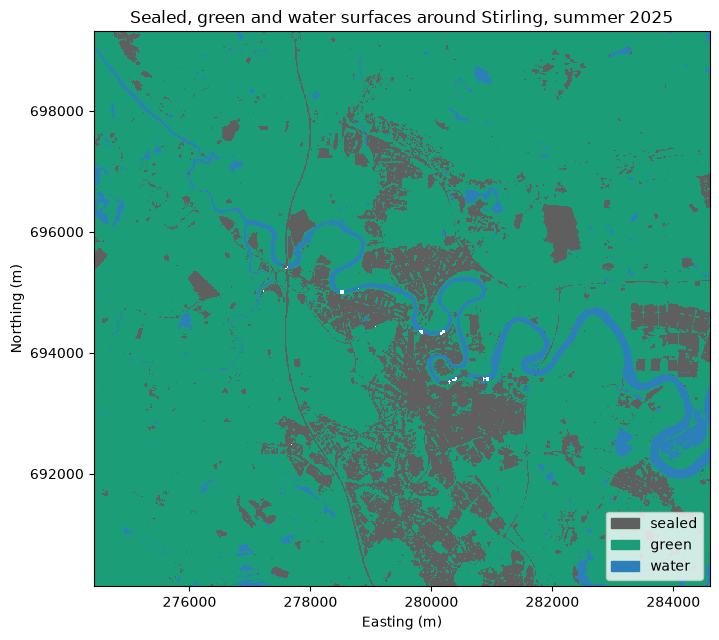

,percent of mapped area
green,80.9
sealed,15.2
water,3.9


In [13]:
pixels = np.stack([stack[name].values.ravel() for name in FEATURES], axis=1)
usable = np.isfinite(pixels).all(axis=1)
class_map = np.zeros(pixels.shape[0], dtype="uint8")
class_map[usable] = forest.predict(pixels[usable])
class_map = class_map.reshape(H, W)

prediction = xr.DataArray(class_map, coords={"y": stack.y, "x": stack.x}, dims=("y", "x"), name="class")
prediction = prediction.rio.write_crs(CRS).rio.write_nodata(0)
prediction.rio.to_raster(DATA / "lab1_prediction.tif")

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.imshow(np.ma.masked_equal(class_map, 0), extent=extent, cmap=ListedColormap(COLOURS), vmin=1, vmax=3,
          interpolation="nearest")
ax.legend(handles=[Patch(color=c, label=n) for c, n in zip(COLOURS, CLASSES.values())], loc="lower right")
ax.set_title("Sealed, green and water surfaces around Stirling, summer 2025")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
plt.tight_layout()
fig.savefig(FIGURES / "lab1_class_map.png", dpi=120)
plt.show()
shares = pd.Series(class_map[class_map > 0]).map(CLASSES).value_counts(normalize=True).mul(100).round(1)
shares.to_frame("percent of mapped area")

## 9. GIS overlay with OS Open Greenspace

OS Open Greenspace maps parks, playing fields, cemeteries and other green sites across Great Britain. We clip it to
the study area and ask what share of each type of site our map calls green or sealed. This is a zonal summary, a
routine GIS operation that links a raster to vector features.

**Predict.** Which kind of greenspace will look least green from space?

In [14]:
gs_zip = DATA / "opgrsp_gpkg_gb.zip"
if not gs_zip.exists():
    urllib.request.urlretrieve(
        "https://api.os.uk/downloads/v1/products/OpenGreenspace/downloads?area=GB&format=GeoPackage&redirect", gs_zip)
gs_dir = DATA / "os_open_greenspace"
if not gs_dir.exists():
    with zipfile.ZipFile(gs_zip) as archive:
        archive.extractall(gs_dir)
gpkg = next(gs_dir.rglob("*.gpkg"))

study_area = gpd.GeoSeries([box(*BBOX)], crs="EPSG:4326").to_crs(CRS)
sites = gpd.read_file(gpkg, layer="greenspace_site", bbox=tuple(study_area.total_bounds)).clip(study_area)

transform = prediction.rio.transform()
summary = []
for function, group in sites.groupby("function"):
    inside = ~geometry_mask(group.geometry, out_shape=(H, W), transform=transform)
    classes_inside = class_map[inside]
    classes_inside = classes_inside[classes_inside > 0]
    summary.append({"site type": function, "sites": len(group), "pixels": classes_inside.size,
                    "green %": round(100 * np.mean(classes_inside == 2), 1),
                    "sealed %": round(100 * np.mean(classes_inside == 1), 1)})
summary = pd.DataFrame(summary).sort_values("green %").reset_index(drop=True)
summary

,site type,sites,pixels,green %,sealed %
0,Tennis Court,5,151,62.9,37.1
1,Other Sports Facility,17,2365,63.3,33.7
2,Religious Grounds,17,1136,66.4,33.6
3,Bowling Green,12,312,80.1,19.9
4,Play Space,42,847,93.9,6.1
5,Playing Field,21,6236,94.4,4.8
6,Allotments Or Community Growing Spaces,3,336,94.6,3.6
7,Cemetery,10,1261,97.1,2.9
8,Public Park Or Garden,32,6777,97.9,1.9
9,Golf Course,3,8885,98.9,1.0


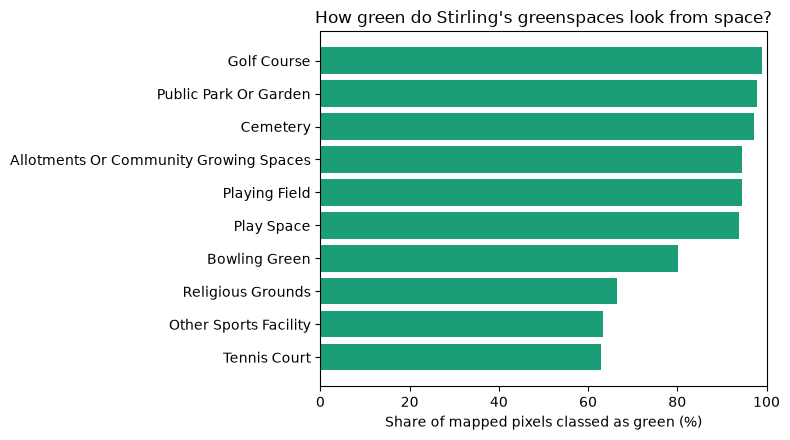

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(summary["site type"], summary["green %"], color=COLOURS[1])
ax.set_xlabel("Share of mapped pixels classed as green (%)")
ax.set_xlim(0, 100)
ax.set_title("How green do Stirling's greenspaces look from space?")
plt.tight_layout()
plt.show()

**Investigate.**
1. Which site types look least green? Think about tennis courts, play spaces and religious grounds.
2. Many small sites cover only a few 10 m pixels. How does that affect the percentages?
3. OS Open Greenspace records what a site is for, while the satellite records what covers it. Why can both be right
   and still disagree?

In [16]:
stack["label"] = labels
stack = stack.drop_vars([c for c in stack.coords if c not in ("x", "y")])
stack.to_netcdf(DATA / "lab1_stack.nc")
train.to_csv(DATA / "lab1_training_pixels.csv", index=False)
print("Saved the feature stack and training pixels for Lab 2.")

Saved the feature stack and training pixels for Lab 2.


## 10. Make and reflect

**Make.** Change `BBOX` to another Scottish town, for example Falkirk or Perth, and run the notebook again. The
assessment brief in `teaching/assessment_brief.md` builds on this step.

**Reflect.**
1. Your labels came from another model, WorldCover 2021. What kinds of error could this bring into your map?
2. Your test pixels came from the same squares as your training pixels. Could that make your accuracy look better
   than it is? Lab 2 tests exactly this.

## Data credits
- Contains modified Copernicus Sentinel data (2025), accessed through the Microsoft Planetary Computer.
- ESA WorldCover 10 m 2021 v200, Zanaga et al. (2022), CC BY 4.0.
- Contains OS data © Crown copyright and database rights 2026, OS Open Greenspace under the OS OpenData licence.